# RQ3 Analysis: Reading Ease

Compares the reading ease (Flesch Kincaid Grade Level) of human-written vs. LLM-generated PR descriptions.

- Uses `textstat.flesch_kincaid_grade` to compute the score.
- Compares across models and prompt context variations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import textstat
from scipy.stats import mannwhitneyu, kruskal
import scikit_posthocs as sp

# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [2]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'
df = pd.read_csv(csv_path)

variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: ['meta-llama/llama-3.1-70b-instruct' 'gpt-5-mini-2025-08-07'
 'Qwen/Qwen2.5-72B-Instruct']
Human entries: 308, AI entries: 5528


## 2. Compute Flesch Kincaid Grade Level

In [3]:
def compute_reading_ease(text):
    """Compute Flesch Kincaid Grade Level for a given text."""
    if pd.isna(text) or str(text).strip() == '':
        return np.nan
    text = str(text)
    return textstat.flesch_kincaid_grade(text)

# Apply to both subsets
human_df['flesch_kincaid_grade'] = human_df['text'].apply(compute_reading_ease)
ai_df['flesch_kincaid_grade'] = ai_df['text'].apply(compute_reading_ease)

# Combine for analysis
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
combined_df['source'] = combined_df['entry_type'].map({'human': 'Human', 'ai': 'AI'})
combined_df = combined_df.dropna(subset=['flesch_kincaid_grade'])

print("Reading ease metrics computed.")
print(f"Combined dataset size: {len(combined_df)}")
display(combined_df[['entry_type', 'model', 'text', 'flesch_kincaid_grade']].head(10))

Reading ease metrics computed.
Combined dataset size: 5836


,entry_type,model,text,flesch_kincaid_grade
0,human,Human,Fixes #8873 \r\n\r\n\r\n<!-- \r\n- Go through ...,11.594856
1,human,Human,"Implements #1516. Selected fields (`ISBN`, `UR...",7.877609
2,human,Human,"Fixes #8108 \r\n\r\nTheoretically works, but n...",10.611371
3,human,Human,Fixes #3905\r\n\r\n<!-- describe the changes y...,12.492117
4,human,Human,Fixes #2676\r\n,2.890000
5,human,Human,Fixes #8654\r\nThis allows for the right click...,11.035047
6,human,Human,# Changed database structure: table names are ...,12.022209
7,human,Human,See #2789.\r\n> JabRef version 4.0.0-beta on W...,7.981250
8,human,Human,Fixes #3584\r\n\r\n(No changelod needed as thi...,10.420750
9,human,Human,…tting down\r\n\r\nFixes #2486. Unregistering ...,7.527500


## 3. Descriptive Statistics: Human vs AI (Overall)

In [4]:
print(f"\n{'='*60}")
print("  Flesch Kincaid Grade Level — Descriptive Statistics")
print(f"{'='*60}")

stats = combined_df.groupby('source')['flesch_kincaid_grade'].describe()
stats['median'] = combined_df.groupby('source')['flesch_kincaid_grade'].median()
display(stats)

for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['flesch_kincaid_grade']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.2f}, Median={vals.median():.2f}, Q3={q3:.2f}, IQR={q3 - q1:.2f}")


  Flesch Kincaid Grade Level — Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5528.0,12.780965,3.107421,-0.723889,10.889818,12.626648,14.434162,87.898,12.626648
Human,308.0,11.146668,3.869382,-3.010000,9.501806,11.073795,12.939829,44.190,11.073795


  Human: Q1=9.50, Median=11.07, Q3=12.94, IQR=3.44
  AI: Q1=10.89, Median=12.63, Q3=14.43, IQR=3.54


## 4. Descriptive Statistics: By Model

In [5]:
print(f"\n{'='*60}")
print("  Flesch Kincaid Grade Level — By Model")
print(f"{'='*60}")

stats_model = combined_df.groupby('model')['flesch_kincaid_grade'].describe()
stats_model['Median'] = combined_df.groupby('model')['flesch_kincaid_grade'].median()
stats_model['Q1'] = combined_df.groupby('model')['flesch_kincaid_grade'].quantile(0.25)
stats_model['Q3'] = combined_df.groupby('model')['flesch_kincaid_grade'].quantile(0.75)
stats_model['IQR'] = stats_model['Q3'] - stats_model['Q1']

display(stats_model[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}))


  Flesch Kincaid Grade Level — By Model


,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,308.0,11.146668,3.869382,11.073795,9.501806,12.939829,3.438022
Qwen/Qwen2.5-72B-Instruct,1842.0,12.594573,2.238058,12.565000,11.036133,14.102266,3.066133
gpt-5-mini-2025-08-07,1842.0,13.272955,3.296673,12.950685,11.467535,14.644826,3.177291
meta-llama/llama-3.1-70b-instruct,1844.0,12.475698,3.567646,12.240958,10.054019,14.606592,4.552573


## 5. Statistical Testing & Effect Size

In [6]:
def cliffs_delta(lst1, lst2):
    """Compute Cliff's Delta effect size."""
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y: dom += 1
            elif x < y: dom -= 1
    return dom / (m * n)

def interpret_cliffs_delta(d):
    d = abs(d)
    if d < 0.147: return "Negligible"
    elif d < 0.33: return "Small"
    elif d < 0.474: return "Medium"
    else: return "Large"

model_results = []

human_fkg = combined_df[combined_df['source'] == 'Human']['flesch_kincaid_grade'].values

for model in ai_df['model'].unique():
    model_data = ai_df[ai_df['model'] == model]

    for metric, human_vals in [('Flesch Kincaid Grade', human_fkg)]:
        col = 'flesch_kincaid_grade'
        ai_vals = model_data[col].values

        stat, p = mannwhitneyu(human_vals, ai_vals, alternative='two-sided')
        cd = cliffs_delta(human_vals.tolist(), ai_vals.tolist())

        model_results.append({
            'Model': model,
            'Metric': metric,
            'Human Mean': np.mean(human_vals),
            'Model Mean': np.mean(ai_vals),
            'Human Median': np.median(human_vals),
            'Model Median': np.median(ai_vals),
            'U-Statistic': stat,
            'p-value': p,
            'Significant': 'Yes' if p < 0.05 else 'No',
            "Cliff's Delta": round(cd, 4),
            'Effect Size': interpret_cliffs_delta(cd)
        })

models = ai_df['model'].unique()

print(models)
model_results_df = pd.DataFrame(model_results)
display(model_results_df)

['meta-llama/llama-3.1-70b-instruct' 'gpt-5-mini-2025-08-07'
 'Qwen/Qwen2.5-72B-Instruct']


,Model,Metric,Human Mean,Model Mean,Human Median,Model Median,U-Statistic,p-value,Significant,Cliff's Delta,Effect Size
0,meta-llama/llama-3.1-70b-instruct,Flesch Kincaid Grade,11.146668,12.475698,11.073795,12.240958,224276.0,3.338318e-09,Yes,-0.2102,Small
1,gpt-5-mini-2025-08-07,Flesch Kincaid Grade,11.146668,13.272955,11.073795,12.950685,165153.0,6.874725e-32,Yes,-0.4178,Medium
2,Qwen/Qwen2.5-72B-Instruct,Flesch Kincaid Grade,11.146668,12.594573,11.073795,12.565000,192133.5,1.118137e-19,Yes,-0.3227,Small


## 6. Visualizations

/var/folders/d5/kbf1hcvs4sl927g49_qn2x7c0000gn/T/ipykernel_46283/2060655888.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_df, x='flesch_kincaid_grade', y='source', palette='Set2')


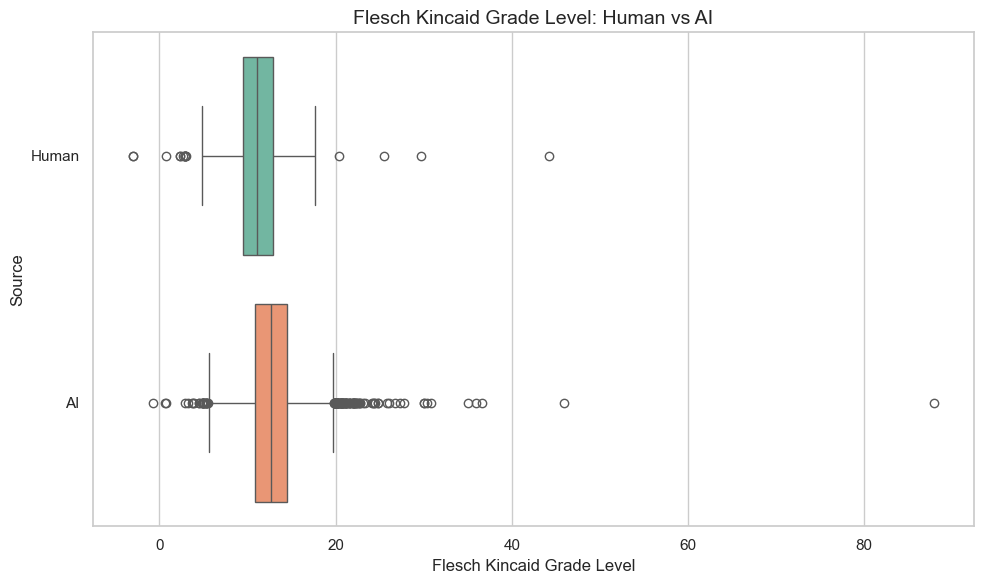

/var/folders/d5/kbf1hcvs4sl927g49_qn2x7c0000gn/T/ipykernel_46283/2060655888.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_df, x='flesch_kincaid_grade', y='model', order=order, palette='Set2')


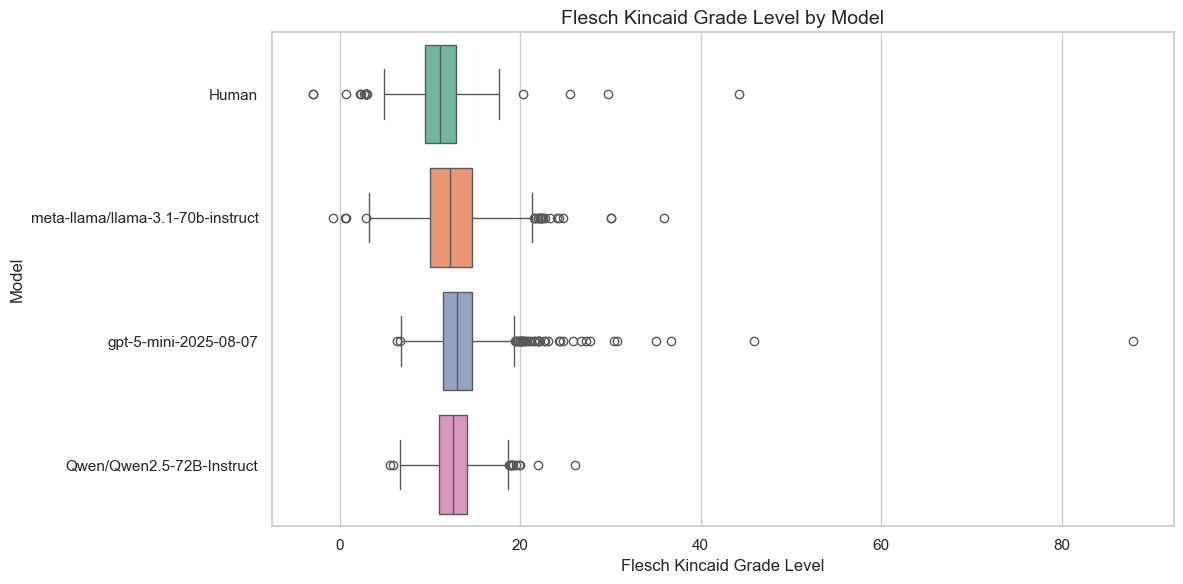

In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_df, x='flesch_kincaid_grade', y='source', palette='Set2')
plt.xlabel("Flesch Kincaid Grade Level", fontsize=12)
plt.ylabel("Source", fontsize=12)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
order = ['Human'] + list(models)
sns.boxplot(data=combined_df, x='flesch_kincaid_grade', y='model', order=order, palette='Set2')
plt.xlabel("Flesch Kincaid Grade Level", fontsize=12)
plt.ylabel("Model", fontsize=12)
plt.tight_layout()
plt.show()

## 7. FKGL Boxplots by Context per LLM (with Human Baseline)

This mirrors the word-count and sentence-count setup:

- One panel per LLM model (stacked vertically).
- Each panel includes 6 AI context boxplots.
- A Human baseline FKGL boxplot is included in each panel for direct comparison.


  Flesch Kincaid Grade Level — By Prompt Context Variation


,count,mean,std,min,25%,50%,75%,max,median
Context_Name,,,,,,,,,
File Contents,908.0,14.083358,3.295860,-0.723889,12.302623,13.943073,15.457135,45.915863,13.943073
File Diff,924.0,12.976696,2.890990,3.653333,11.111626,12.902209,14.782699,24.287097,12.902209
Linked Issue,924.0,11.226833,2.258968,5.579722,9.760104,11.052980,12.436969,22.312308,11.052980
PR Title,924.0,13.350977,2.760321,5.825435,11.555861,13.166908,14.665500,35.013396,13.166908
Repo Path,924.0,13.311388,3.708831,3.280000,11.617045,13.149137,14.716233,87.898000,13.149137
Without File Contents,924.0,11.759092,2.556193,0.625714,9.995617,11.721163,13.250266,24.786966,11.721163


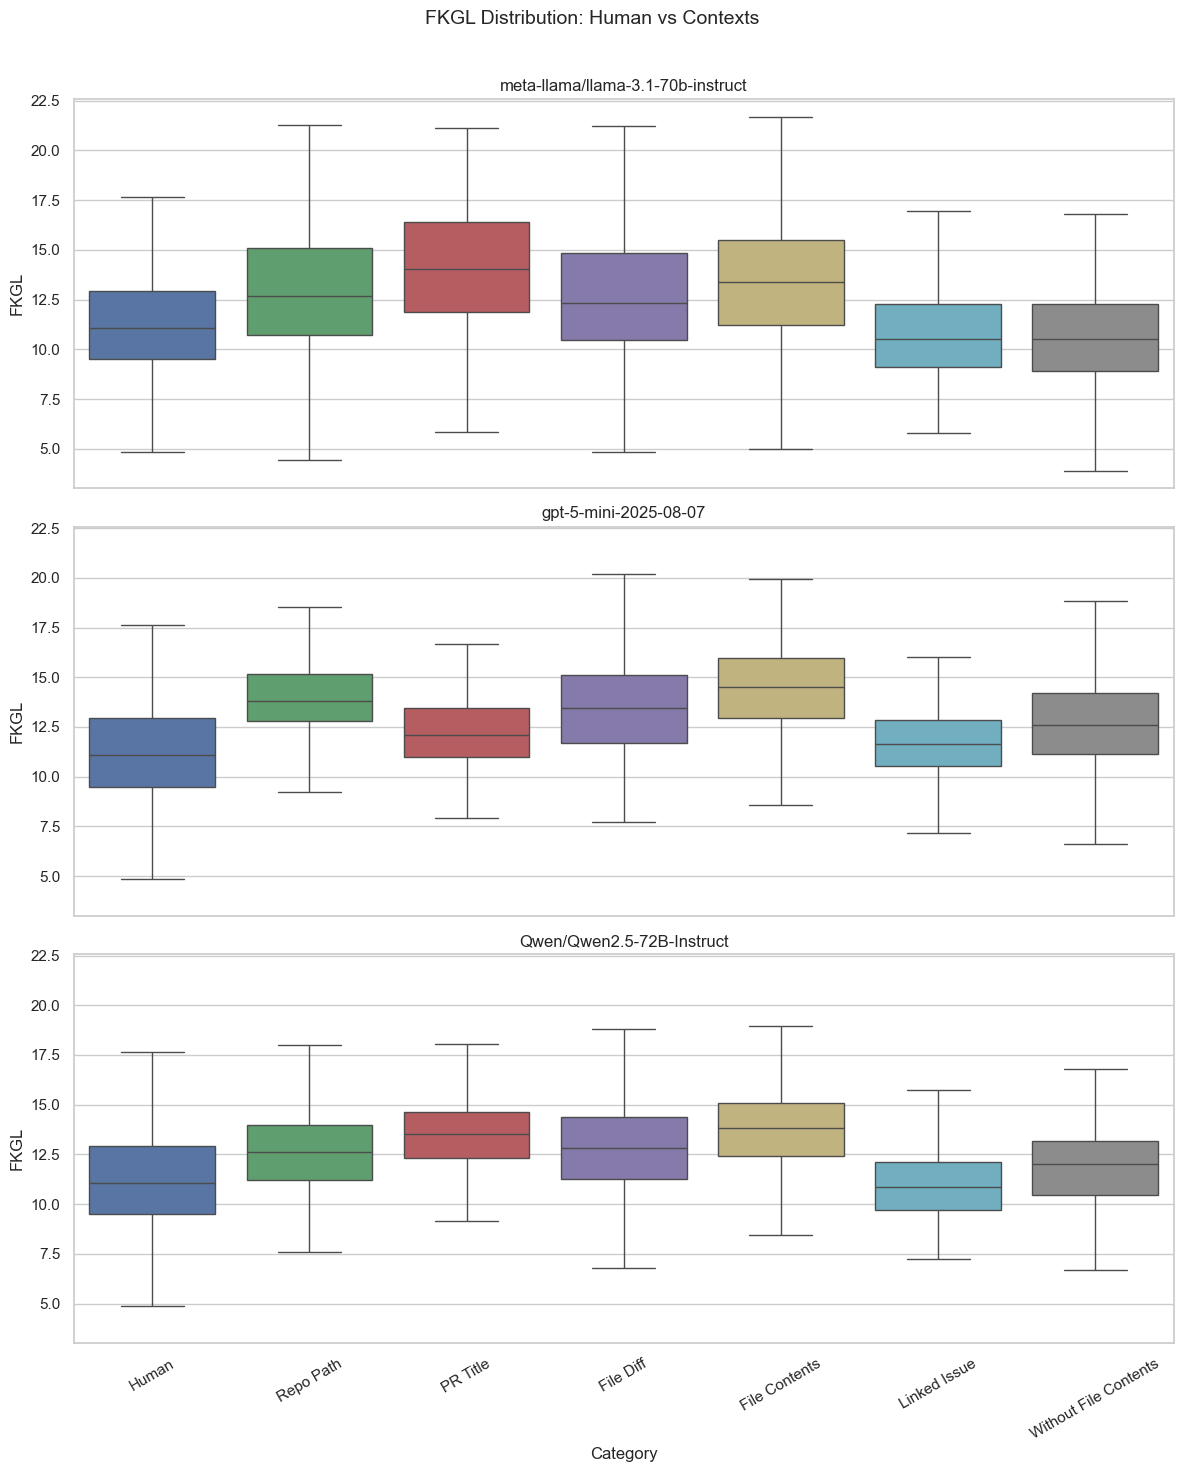

In [4]:
print(f"\n{'='*60}")
print("  Flesch Kincaid Grade Level — By Prompt Context Variation")
print(f"{'='*60}")

# Keep descriptive stats on AI context variation only.
context_df = combined_df[combined_df['source'] == 'AI'].copy()
stats_ctx = context_df.groupby('Context_Name')['flesch_kincaid_grade'].describe()
stats_ctx['median'] = context_df.groupby('Context_Name')['flesch_kincaid_grade'].median()
display(stats_ctx)

context_order = [
    'Repo Path',
    'PR Title',
    'File Diff',
    'File Contents',
    'Linked Issue',
    'Without File Contents'
]

llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=14)

    ai_slice = ai_df[ai_df['model'] == model][['flesch_kincaid_grade', 'Context_Name']].copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['flesch_kincaid_grade']].copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['flesch_kincaid_grade', 'Category']],
        ai_slice[['flesch_kincaid_grade', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='flesch_kincaid_grade',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=14)
    ax.set_ylabel('FKGL', fontsize=14)
    ax.tick_params(axis='x', rotation=30, labelsize=12)

plt.tight_layout()
from pathlib import Path
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'fkgl.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 8. Human vs. AI Context Variations (Cliff's δ Effect Sizes per Model)

For each model and each prompt context variation, we compare the paired Human descriptions against the AI-generated descriptions using Cliff's δ effect size measure for Flesch Kincaid Grade Level.

In [9]:
print(f"\n{'='*90}")
print("  Cliff's δ Effect Sizes: Human vs. AI Context Variations (Flesch Kincaid Grade Level)")
print(f"{'='*90}")

model_names = ai_df['model'].unique()
variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

rows = []
for model in model_names:
    row = {'Model': model}
    for variation in variation_names:
        # AI values for this model + variation (only paired PRs)
        ai_vals = ai_df[
            (ai_df['model'] == model) & (ai_df['Context_Name'] == variation)
        ]['flesch_kincaid_grade'].values

        # Human values for the same paired PRs
        human_vals = human_df['flesch_kincaid_grade'].values

        # Compute Cliff's delta
        delta = cliffs_delta(list(human_vals), list(ai_vals))
        interpretation = interpret_cliffs_delta(delta)

        row[variation] = f"{delta:.3f} ({interpretation})"

    rows.append(row)

result_df = pd.DataFrame(rows)
result_df = result_df.set_index('Model')
display(result_df)


  Cliff's δ Effect Sizes: Human vs. AI Context Variations (Flesch Kincaid Grade Level)


,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,-0.323 (Small),-0.509 (Large),-0.254 (Small),-0.406 (Medium),0.100 (Negligible),0.129 (Negligible)
gpt-5-mini-2025-08-07,-0.617 (Large),-0.277 (Small),-0.465 (Medium),-0.668 (Large),-0.140 (Negligible),-0.344 (Medium)
Qwen/Qwen2.5-72B-Instruct,-0.344 (Medium),-0.533 (Large),-0.361 (Medium),-0.581 (Large),0.044 (Negligible),-0.166 (Small)


## 9. Summary Table

In [10]:
summary_rows = []

for model in combined_df['model'].unique():
    vals = combined_df[combined_df['model'] == model]['flesch_kincaid_grade']
    summary_rows.append({
        'Model': model,
        'Metric': 'Flesch Kincaid Grade Level',
        'N': len(vals),
        'Mean': round(vals.mean(), 2),
        'Median': round(vals.median(), 2),
        'Std': round(vals.std(), 2),
        'Min': round(vals.min(), 2),
        'Max': round(vals.max(), 2),
        'Q1': round(vals.quantile(0.25), 2),
        'Q3': round(vals.quantile(0.75), 2)
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

import os
os.makedirs('outputs', exist_ok=True)

# Save summary to CSV
summary_df.to_csv('outputs/rq3_reading_ease_summary.csv', index=False)
print("\nSummary saved to outputs/rq3_reading_ease_summary.csv")

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,Flesch Kincaid Grade Level,308,11.15,11.07,3.87,-3.01,44.19,9.50,12.94
1,meta-llama/llama-3.1-70b-instruct,Flesch Kincaid Grade Level,1844,12.48,12.24,3.57,-0.72,35.96,10.05,14.61
2,gpt-5-mini-2025-08-07,Flesch Kincaid Grade Level,1842,13.27,12.95,3.30,6.34,87.90,11.47,14.64
3,Qwen/Qwen2.5-72B-Instruct,Flesch Kincaid Grade Level,1842,12.59,12.57,2.24,5.58,26.05,11.04,14.10



Summary saved to outputs/rq3_reading_ease_summary.csv
